In [1]:
import sys
from pathlib import Path

import pandas as pd

project_root = Path.cwd().parent
sys.path.append(f"{project_root}\\src")

# Load the dataset
df = pd.read_csv(f"{project_root}/data/ecommerce_sales.csv", parse_dates=["date"])

## Nyckeltal

In [2]:
from metrics import (
    calc_total_revenue,
    calculate_aov,
    calculate_aov_by_month,
    get_sales_by_category,
    get_top_3_categories,
    get_top_3_cities,
)

# Display Total Revenue
print(f"Total revenue:   {calc_total_revenue(df)}")

print("-" * 20)

# Display AOV
print("AOV by month")
for month, aov in calculate_aov_by_month(df).items():
    print(f"{month}:    {aov}")
print("-" * 20)
print("AOV by category")
for category in get_sales_by_category(df):
    print(f"{category.category_name}:    {category.calc_aov()}")
print("-" * 20)
print(f"Combined AOV:    {calculate_aov(df)}")

print("-" * 20)

# Display top 3 cities by revenue
print("Top 3 Cities by Revenue:")
display(
    get_top_3_cities(df)
    .style
    .hide(axis="index")
    .format({"total_revenue": lambda x: f"{x:.3f}".rstrip("0").rstrip(".")})
)

# Display top 3 categories by revenue
print("Top 3 Categories by Revenue:")
display(
    get_top_3_categories(df)
    .style
    .hide(axis="index")
    .format({"total_revenue": lambda x: f"{x:.3f}".rstrip("0").rstrip(".")})
)

Total revenue:   3502767.23
--------------------
AOV by month
January:    1492.32
February:    1536.31
March:    1186.38
April:    1343.04
May:    1459.97
June:    1398.72
--------------------
AOV by category
Sports:    1770.25
Clothing:    1152.74
Home:    1043.0
Electronics:    2207.49
Toys:    630.03
Beauty:    676.57
--------------------
Combined AOV:    1401.11
--------------------
Top 3 Cities by Revenue:


city,total_revenue
Stockholm,1227201.94
Göteborg,859019.65
Malmö,567926.32


Top 3 Categories by Revenue:


category,total_revenue
Electronics,1364228.07
Sports,734653.42
Clothing,586744.91


## Visualiseringar

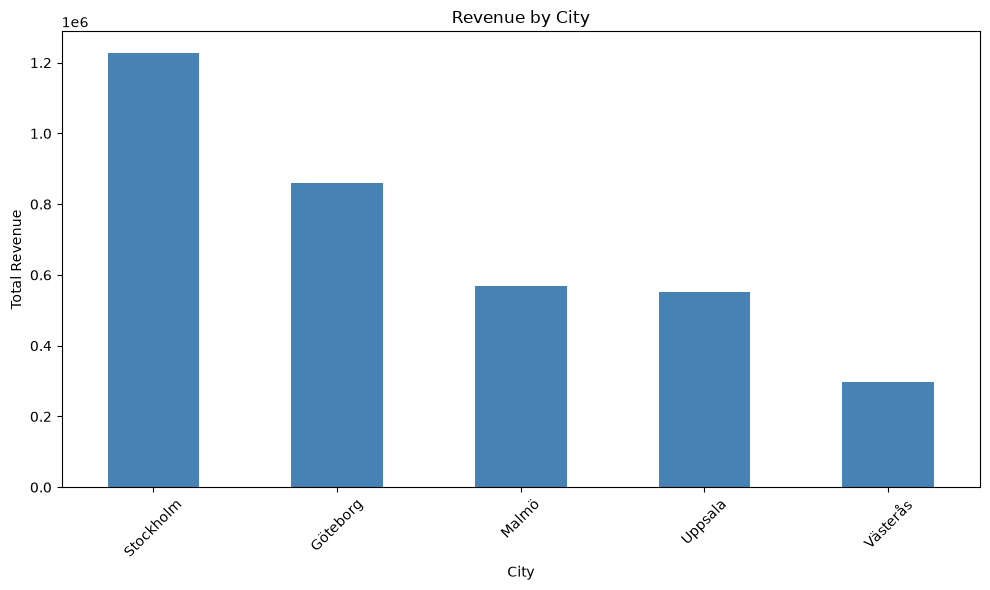

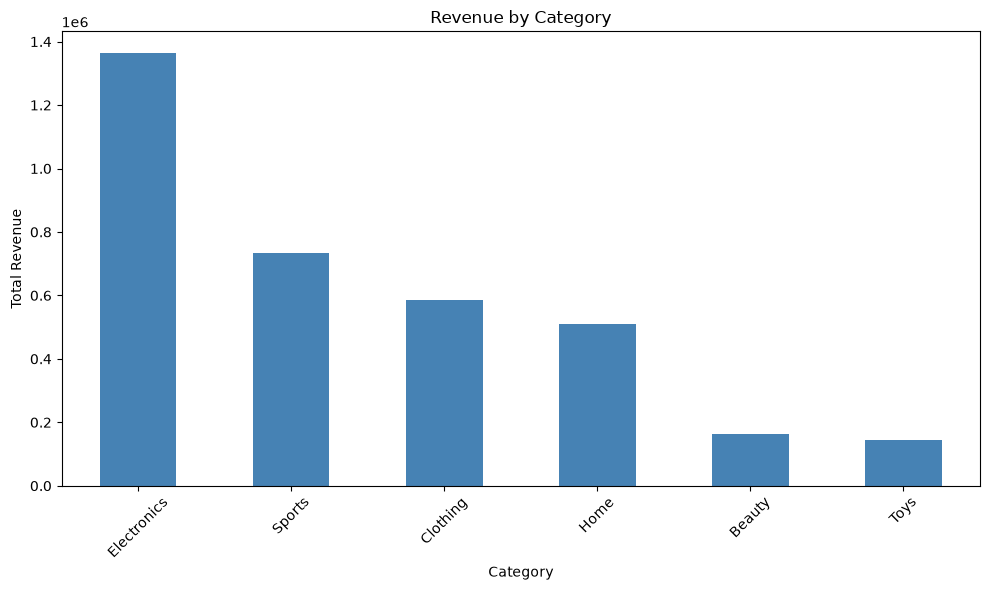

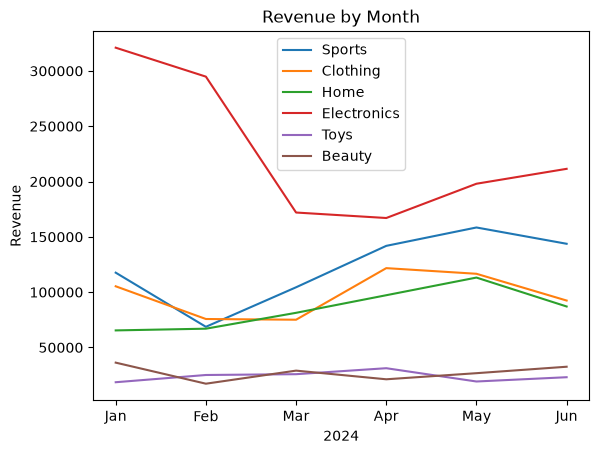

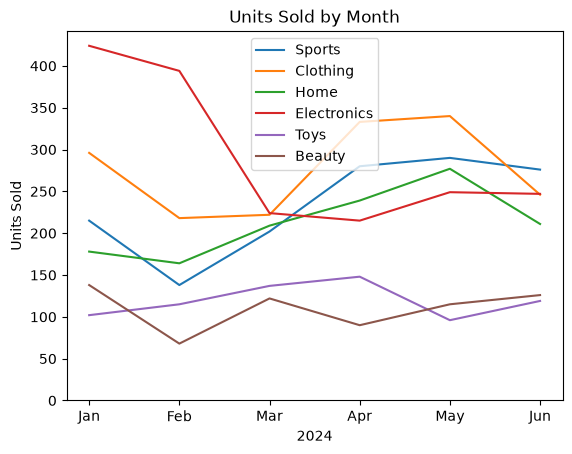

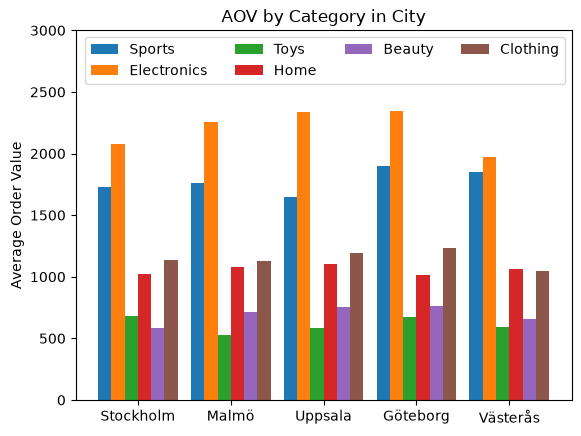

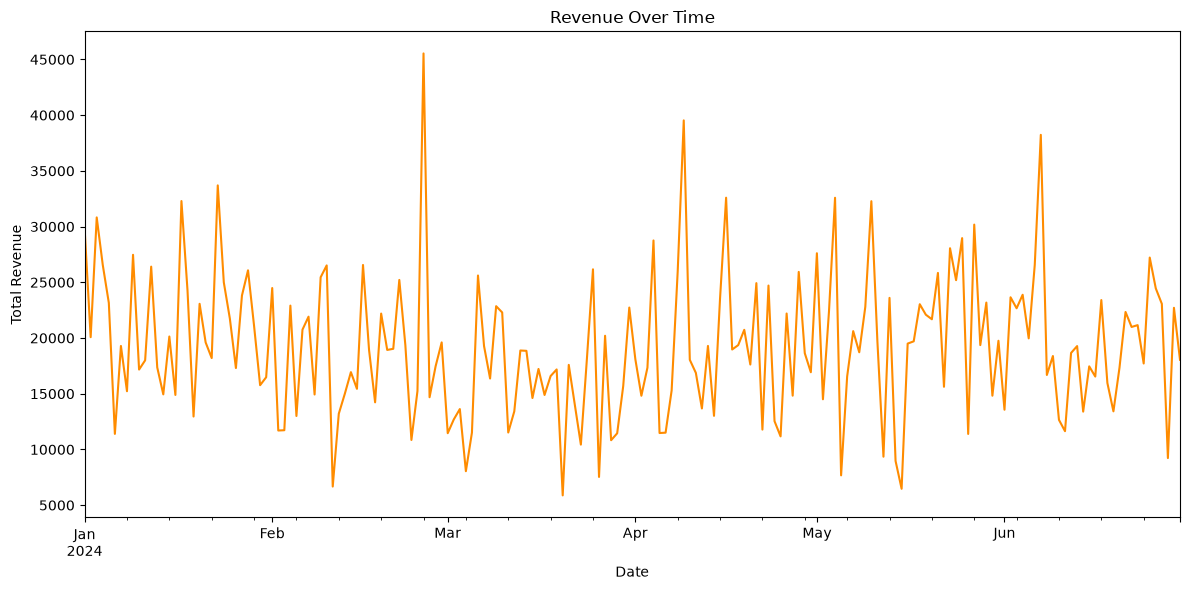

In [3]:
from metrics import (
    get_sales_by_category,
    get_sales_by_city,
)
from viz import (
    plot_aov_by_city_and_category,
    plot_revenue_by_category,
    plot_revenue_by_category_over_time,
    plot_revenue_over_time,
    plot_units_sold_by_category_over_time,
)

plot_revenue_by_category(
    df,
    category_column="city",
    title="Revenue by City"
)

plot_revenue_by_category(
    df,
    category_column="category",
    title="Revenue by Category"
)

categories = get_sales_by_category(df)
city_sales = get_sales_by_city(df)
plot_revenue_by_category_over_time(categories)
plot_units_sold_by_category_over_time(categories)
plot_aov_by_city_and_category(city_sales)

plot_revenue_over_time(df);